# Laboratory 1

**Before you start:** 
1. install mmseqs2 using https://github.com/soedinglab/mmseqs2
2. run `fetch_data.sh`

In [1]:
import subprocess
import collections
import sys
import pandas as pd

foldcomp, mmseqs2, hh-suite, scikit-bio

## Helpers

In [2]:
def run(cmd, log_file=None):
    out_target = (
        open(log_file, "a", encoding="utf-8") if log_file else subprocess.DEVNULL
    )
    err_target = out_target if log_file else sys.stderr

    r = subprocess.run(cmd, shell=True, stdout=out_target, stderr=err_target, text=True)

    if log_file:
        out_target.close()

    if r.returncode:
        raise RuntimeError(f"Command failed with exit code {r.returncode}")

In [3]:
def cluster_stats(tsv):
    """*_cluster.tsv is: representative <TAB> member"""
    n = collections.Counter(l.split("\t")[0] for l in open(tsv))
    s = list(n.values())
    return dict(
        clusters=len(n),
        avg_size=round(sum(s) / len(n), 2),
        singletons=sum(1 for x in s if x == 1),
        largest=max(s),
    )

## Setup

In [5]:
run("rm -rf work && mkdir -p work")

MMSEQS = str("/usr/local/bin/mmseqs")

print(
    subprocess.run(
        f"{MMSEQS} version", shell=True, capture_output=True, text=True
    ).stdout.strip()
)

564f40d8857f4eca4e1dfe100c67c155b1933e70


## A — Clustering

- **Bit score** — how good the alignment is relative to a scoring system (higher is better)
- **E-value** — how many alignments with a score at least this good would be expected by chance in the search database (lower is better)
- **Sequence identity** — exact residue agreement (usually used with coverage parameter)

### `easy-cluster`

`--min-seq-id` is how *similar* the aligned part must be; `-c` is how *much* of
each sequence must be aligned. They are independent, and `--cov-mode` decides
which sequence the coverage applies to (`0` = both).

In [6]:
%%time
run(
    f"{MMSEQS} easy-cluster data/globins.fasta work/clu50 work/tmp "
    f"--min-seq-id 0.5 -c 0.8 --cov-mode 0",
    "work/clu50.log",
)

CPU times: user 1.68 ms, sys: 5.2 ms, total: 6.88 ms
Wall time: 19.9 s


In [7]:
cluster_stats("work/clu50_cluster.tsv")

{'clusters': 106, 'avg_size': 11.33, 'singletons': 56, 'largest': 364}

Three output files: 
- `_cluster.tsv`: representative (cluster centroid) → member
- `_rep_seq.fasta`: one sequence per cluster (**non-redundant set**)
- `_all_seqs.fasta`: cluster centroids and member sequences listed below

### `easy-linclust`

`cluster` prefilters then aligns every surviving pair; `linclust` only compares
sequences sharing a k-mer representative, which is O(N) instead of O(N²).

In [8]:
%%time
run(
    f"{MMSEQS} easy-linclust data/globins.fasta work/lin50 work/tmp "
    f"--min-seq-id 0.5 -c 0.8 --cov-mode 0",
    "work/lin50.log",
)

CPU times: user 5.05 ms, sys: 655 μs, total: 5.7 ms
Wall time: 7.46 s


In [9]:
pd.DataFrame(
    {
        "cluster": cluster_stats("work/clu50_cluster.tsv"),
        "linclust": cluster_stats("work/lin50_cluster.tsv"),
    }
)

,cluster,linclust
clusters,106.00,129.00
avg_size,11.33,9.31
singletons,56.00,73.00
largest,364.00,355.00


## B — Search and MSA

A FASTA file is not searchable: `createdb` builds the index structures first. Then we run `search` and `result2msa`.

In [10]:
run("rm -rf work/msa && mkdir -p work/msa")

In [11]:
log_file = "work/msa/msa.log"

run(f"{MMSEQS} createdb data/query.fasta work/msa/queryDB", log_file)
run(f"{MMSEQS} createdb data/target_1000.fasta work/msa/targetDB", log_file)
run(
    f"{MMSEQS} search work/msa/queryDB work/msa/targetDB work/msa/resultDB work/msa/tmp -e 1e-3",
    log_file,
)
run(
    f"{MMSEQS} convertalis work/msa/queryDB work/msa/targetDB work/msa/resultDB work/msa/hits.m8 "
    f"--format-output 'query,target,fident,alnlen,evalue,bits'",
    log_file,
)

msa_hits = pd.read_csv(
    "work/msa/hits.m8",
    sep="\t",
    names=["query", "target", "identity", "alnlen", "evalue", "bits"],
)

In [12]:
msa_hits

,query,target,identity,alnlen,evalue,bits
0,P68871,P68871,0.996,147,5.486000e-100,312
1,P68871,P02042,0.936,147,1.014000e-92,291
2,P68871,P02100,0.800,147,2.877000e-76,243
3,P68871,P69892,0.784,147,2.391000e-74,238
4,P68871,P69891,0.774,147,4.097000e-73,234
5,P68871,P69905,0.447,143,1.512000e-32,117
6,P68871,P09105,0.385,143,2.678000e-25,96
7,P68871,Q6B0K9,0.357,143,5.065000e-22,87


Matplotlib is building the font cache; this may take a moment.


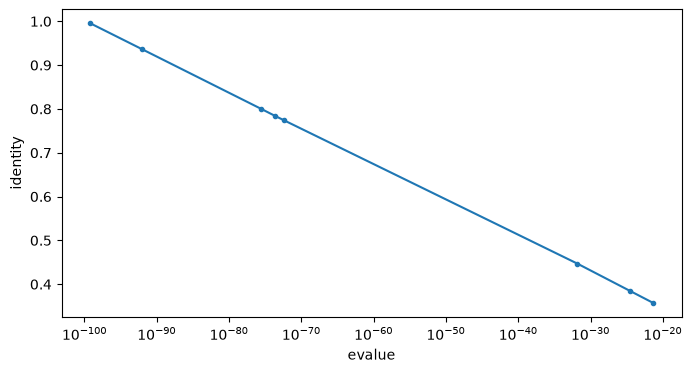

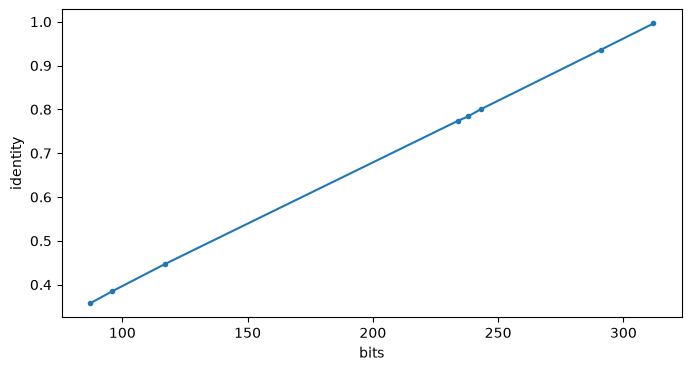

In [13]:
msa_hits.plot(
    x="evalue",
    y="identity",
    style=".-",
    figsize=(8, 4),
    ylabel="identity",
    legend=False,
    logx=True,
)
msa_hits.plot(
    x="bits", y="identity", style=".-", figsize=(8, 4), ylabel="identity", legend=False
)

`--msa-format-mode`: `2` = aligned FASTA, `5` = **a3m** (what HH-suite and
AlphaFold consume). Modes `0`/`1` are *binary* cA3M databases that `unpackdb`
cannot read — a common trap.

In [14]:
run(
    f"{MMSEQS} result2msa work/msa/queryDB work/msa/targetDB work/msa/resultDB work/msa/msaDB "
    f"--msa-format-mode 2",
    log_file,
)
run(f"{MMSEQS} unpackdb work/msa/msaDB work/msa --unpack-name-mode 0", log_file)

for line in open("work/msa/0").read().splitlines():
    print(line[:78])

>sp|P68871|HBB_HUMAN Hemoglobin subunit beta OS=Homo sapiens OX=9606 GN=HBB PE
MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAH
>sp|P68871|HBB_HUMAN Hemoglobin subunit beta OS=Homo sapiens OX=9606 GN=HBB PE
MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAH
>sp|P02042|HBD_HUMAN Hemoglobin subunit delta OS=Homo sapiens OX=9606 GN=HBD P
MVHLTPEEKTAVNALWGKVNVDAVGGEALGRLLVVYPWTQRFFESFGDLSSPDAVMGNPKVKAHGKKVLGAFSDGLAH
>sp|P02100|HBE_HUMAN Hemoglobin subunit epsilon OS=Homo sapiens OX=9606 GN=HBE
MVHFTAEEKAAVTSLWSKMNVEEAGGEALGRLLVVYPWTQRFFDSFGNLSSPSAILGNPKVKAHGKKVLTSFGDAIKN
>sp|P69892|HBG2_HUMAN Hemoglobin subunit gamma-2 OS=Homo sapiens OX=9606 GN=HB
MGHFTEEDKATITSLWGKVNVEDAGGETLGRLLVVYPWTQRFFDSFGNLSSASAIMGNPKVKAHGKKVLTSLGDAIKH
>sp|P69891|HBG1_HUMAN Hemoglobin subunit gamma-1 OS=Homo sapiens OX=9606 GN=HB
MGHFTEEDKATITSLWGKVNVEDAGGETLGRLLVVYPWTQRFFDSFGNLSSASAIMGNPKVKAHGKKVLTSLGDATKH
>sp|P69905|HBA_HUMAN Hemoglobin subunit alpha OS=Hom

The beta-type globins align end to end; the alpha-type ones (HBA, HBAZ, HBAT)
open a gap at the N-terminus. That gap is the duplication that split the two
lineages.

---
# Exercises

## 1 — How does the identity threshold change the clustering?

- use both `cluster` and `linclust`
- run the above for `min-seq-id` in `[0.1, 0.2, 0.30, 0.50, 0.70, 0.90, 0.95]`
- estimate at which `min-seq-id` the clustering methods give divergent results

In [15]:
%%time
IDS = [0.1, 0.2, 0.30, 0.50, 0.70, 0.90, 0.95]

run("rm -rf work/ex1 && mkdir -p work/ex1")

rows = []
for sid in IDS:
    for method, cmd in [("cluster", "easy-cluster"), ("linclust", "easy-linclust")]:
        prefix = f"work/ex1/{method}_{sid}"
        run(
            f"{MMSEQS} {cmd} data/globins.fasta {prefix} work/ex1/tmp "
            f"--min-seq-id {sid} -c 0.8 --cov-mode 0",
            "work/ex1/ex1.log",
        )
        rows.append(
            dict(
                min_seq_id=sid, method=method, **cluster_stats(f"{prefix}_cluster.tsv")
            )
        )

ex1 = pd.DataFrame(rows)
ex1.pivot(index="min_seq_id", columns="method", values="clusters")

CPU times: user 143 ms, sys: 11 ms, total: 154 ms
Wall time: 1min 21s


method,cluster,linclust
min_seq_id,,
0.10,48,105
0.20,48,105
0.30,53,106
0.50,106,129
0.70,213,218
0.90,525,528
0.95,704,707


In [16]:
def membership(tsv):
    """member -> representative"""
    return dict(l.rstrip("\n").split("\t")[::-1] for l in open(tsv))


def pairs(sizes):
    return sum(n * (n - 1) // 2 for n in sizes)


def pair_jaccard(a, b):
    """Of all pairs put together by at least one method, the fraction put together by both."""
    both = pairs(collections.Counter((a[k], b[k]) for k in a).values())
    return both / (
        pairs(collections.Counter(a.values()).values())
        + pairs(collections.Counter(b.values()).values())
        - both
    )


pd.DataFrame(
    {
        "clusters: cluster": ex1[ex1.method == "cluster"]
        .set_index("min_seq_id")
        .clusters,
        "clusters: linclust": ex1[ex1.method == "linclust"]
        .set_index("min_seq_id")
        .clusters,
        "pair agreement": {
            sid: round(
                pair_jaccard(
                    membership(f"work/ex1/cluster_{sid}_cluster.tsv"),
                    membership(f"work/ex1/linclust_{sid}_cluster.tsv"),
                ),
                3,
            )
            for sid in IDS
        },
    }
)

,clusters: cluster,clusters: linclust,pair agreement
0.10,48,105,0.266
0.20,48,105,0.266
0.30,53,106,0.343
0.50,106,129,0.853
0.70,213,218,0.992
0.90,525,528,0.986
0.95,704,707,0.977


**Result:** the two methods diverge below `min-seq-id` ≈ 0.5.

- At 0.7–0.95 they agree almost perfectly (pair agreement ≥ 0.98, cluster counts within ~1%).
- At 0.5 `cluster` already merges noticeably more (106 vs 129 clusters, agreement 0.85).
- At ≤ 0.3 they are very different (≈ 50 vs ≈ 105 clusters, agreement ≈ 0.3). `linclust` only
  links sequences that share an exact k-mer, so remote homologs are missed and the clusters stay small.
- `cluster` gives identical results at 0.1 and 0.2 (and nearly so at 0.3): below ~0.3 the identity threshold
  stops being the limiting factor, probably because the prefilter only passes pairs above a similarity floor.

## 2 — How does the coverage and coverage mode change the clustering?

- use `cluster` with `min-seq-id 0.5`
- run the above for `cov` in `[0.50, 0.80, 0.95]` and `cov-mode` in `[0, 1, 2, 3]`
- can you spot anything interesting?